In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import sys
sys.path.extend(['/Users/amonast/Documents/GitHub/zlab_miniscope'])
from load_traces import load_aligned_act,build_intervals
import os 
import seaborn as sb
matplotlib.style.use('paper_style.mplstyle')

In [2]:
def plot_pop_mean_eta(act, intervals, event_t, roi_ids=None, window=(-5, 5),ax=None,behavior_labels='all'):
    if roi_ids is None:
        roi_ids = act.columns.drop(['Behavior', 'behavior_type'])
    start = event_t + pd.Timedelta(seconds=window[0])
    end = event_t + pd.Timedelta(seconds=window[1])
    ts = act.index.get_level_values('timestamp')
    act_sub = act[(ts >= start) & (ts <= end)]
    act_long = (act_sub[roi_ids]
            .reset_index()
            .melt(id_vars=['timestamp', 'animal', 'session'], var_name='roi', value_name='activity'))
    act_long['t_sec'] = (act_long['timestamp'] - event_t).dt.total_seconds()
    if ax is None:
        fig,ax=plt.subplots()
    ax = sb.lineplot(data=act_long, x='t_sec', y='activity', errorbar='se',ax=ax)

    behavior_categories = {
        'Aggressive':        "#fe0806",
        'Pro-Social':        "#55a0fb",
        'Social Avoidance':            '#b856d7',}
    behaviors = behavior_categories.keys() if behavior_labels=='all' else behavior_labels
    
    for btype, color in behavior_categories.items():
        bouts = intervals[intervals['behavior_type'] == btype]
        for _, row in bouts.iterrows():
            b_start = (pd.Timedelta(seconds=row['start']) - event_t).total_seconds()
            b_end   = (pd.Timedelta(seconds=row['end'])   - event_t).total_seconds()
            b_start = max(b_start, window[0])
            b_end   = min(b_end,   window[1])
            if b_start < b_end:
                ax.axvspan(b_start, b_end, alpha=0.2, color=color, zorder=0)

    return ax


In [3]:
def first_interaction_time(animal,session,behavior_csv):
    intervals = build_intervals(animal,session,behavior_csv)
    return intervals['start'].loc[intervals['behavior_type'] == 'Pro-Social'].iloc[0]

In [4]:
def mean_population(act,intervals,event_t,roi_ids=None,window=(-5,5)):
    if roi_ids is None:
        roi_ids = act.columns.drop(['Behavior','behavior_type'])
    start = event_t + pd.Timedelta(seconds=window[0])
    end = event_t + pd.Timedelta(seconds=window[1])
    ts = act.index.get_level_values('timestamp')
    act_sub = act[(ts >= start) & (ts <= end)]
    
    pop_mean = act_sub[roi_ids].mean(axis=1)
    time = pop_mean.index.get_level_values('timestamp').total_seconds() - event_t.total_seconds()

    return pop_mean.values,time



In [5]:
base_dir='/Users/amonast/Desktop/miniscope'
traces_dir  = f"{base_dir}/Traces"
behavior_csv = f"{base_dir}/data/tuning/intervals_allmice.csv"
info_csv = f"{base_dir}/dbnst_data_info.csv"
info = pd.read_csv(info_csv)

In [6]:
animals = info.loc[info['Session'] == 'R1', 'Mouse'].unique()
animals

array(['C1F2', 'C1M1', 'C1M2', 'C2F1', 'C2M4', 'C3F3', 'C3F4', 'C3M2',
       'C3M3', 'C3M4'], dtype=object)

In [7]:
for a in animals:
    act = load_aligned_act(a,'R1',
                           traces_dir,behavior_csv,info_csv)
    intervals = build_intervals(a,'R1',behavior_csv)

/Users/amonast/opt/anaconda3/envs/caiman/lib/python3.10/site-packages/pandas/core/tools/datetimes.py:557: RuntimeWarning: invalid value encountered in cast
  arr, tz_parsed = tslib.array_with_unit_to_datetime(arg, unit, errors=errors)


In [8]:
act

0         1         2  \
animal session timestamp                                                 
C3M4   R1      0 days 00:00:00           -0.198867  0.217312 -0.388248   
               0 days 00:00:00.033296128 -0.180139  0.081701 -0.107725   
               0 days 00:00:00.066592    -0.190235 -0.310464  0.002141   
               0 days 00:00:00.099888128 -0.084446  0.268413 -0.814426   
               0 days 00:00:00.133184256 -0.237010  0.166762 -0.050674   
...                                            ...       ...       ...   
               0 days 00:12:29.455248128 -0.449209 -0.292811 -0.611358   
               0 days 00:12:29.488544    -0.427925  0.078473 -0.787317   
               0 days 00:12:29.521840128 -0.242065 -0.258537 -0.454950   
               0 days 00:12:29.555136    -0.277723 -0.225652  0.057045   
               0 days 00:12:29.588431104 -0.339717 -0.503936 -0.613565   

                                                 3         4         5  \
animal session timestamp                                                 
C3M4   R1      0 days 00:00:00           -0.057817 -0.504130 -0.047433   
               0 days 00:00:00.033296128 -0.290817 -0.491951  0.205018   
               0 days 00:00:00.066592     0.008474 -0.221875 -0.149191   
               0 days 00:00:00.099888128  0.477991 -0.474027 -0.233406   
               0 days 00:00:00.133184256 -0.532986 -0.760571 -0.167205   
...                                            ...       ...       ...   
               0 days 00:12:29.455248128  0.089961  0.016047 -0.494518   
               0 days 00:12:29.488544    -0.350838 -0.865787 -0.281748   
               0 days 00:12:29.521840128 -0.136274 -0.271622 -0.261108   
               0 days 00:12:29.555136     0.135548 -0.348618 -0.249641   
               0 days 00:12:29.588431104 -0.284035 -0.579181 -0.227943   

                                                 6         7         8  \
animal session timestamp                                                 
C3M4   R1      0 days 00:00:00            0.643058 -0.517270  0.054049   
               0 days 00:00:00.033296128  0.312218 -1.089337 -0.777486   
               0 days 00:00:00.066592    -0.192293 -1.210161 -0.317626   
               0 days 00:00:00.099888128  0.039702 -0.817754 -0.114084   
               0 days 00:00:00.133184256  0.123801 -0.916705 -1.299107   
...                                            ...       ...       ...   
               0 days 00:12:29.455248128  0.243672 -0.227809  0.576820   
               0 days 00:12:29.488544    -0.178798  0.497492 -0.934683   
               0 days 00:12:29.521840128 -0.616095 -0.154761  0.033557   
               0 days 00:12:29.555136     0.149813 -0.781858  0.472665   
               0 days 00:12:29.588431104 -0.035638  0.010834 -0.297346   

                                                 9  ...        38        39  \
animal session timestamp                            ...                       
C3M4   R1      0 days 00:00:00           -0.388438  ...  0.527658 -0.396961   
               0 days 00:00:00.033296128 -0.360302  ...  0.343370 -0.381977   
               0 days 00:00:00.066592    -0.360144  ... -0.130583 -0.387664   
               0 days 00:00:00.099888128 -0.329754  ...  0.062541 -0.302645   
               0 days 00:00:00.133184256 -0.437692  ... -0.021378 -0.351111   
...                                            ...  ...       ...       ...   
               0 days 00:12:29.455248128 -0.397772  ... -0.305866 -0.333534   
               0 days 00:12:29.488544    -0.396113  ... -0.602670 -0.351049   
               0 days 00:12:29.521840128 -0.303059  ... -0.088348 -0.260468   
               0 days 00:12:29.555136    -0.045152  ... -0.489503 -0.346172   
               0 days 00:12:29.588431104 -0.279991  ... -0.378461 -0.334548   

                                                40        41        42  \
animal session timestamp                                  

/Users/amonast/opt/anaconda3/envs/caiman/lib/python3.10/site-packages/pandas/core/tools/datetimes.py:557: RuntimeWarning: invalid value encountered in cast
  arr, tz_parsed = tslib.array_with_unit_to_datetime(arg, unit, errors=errors)


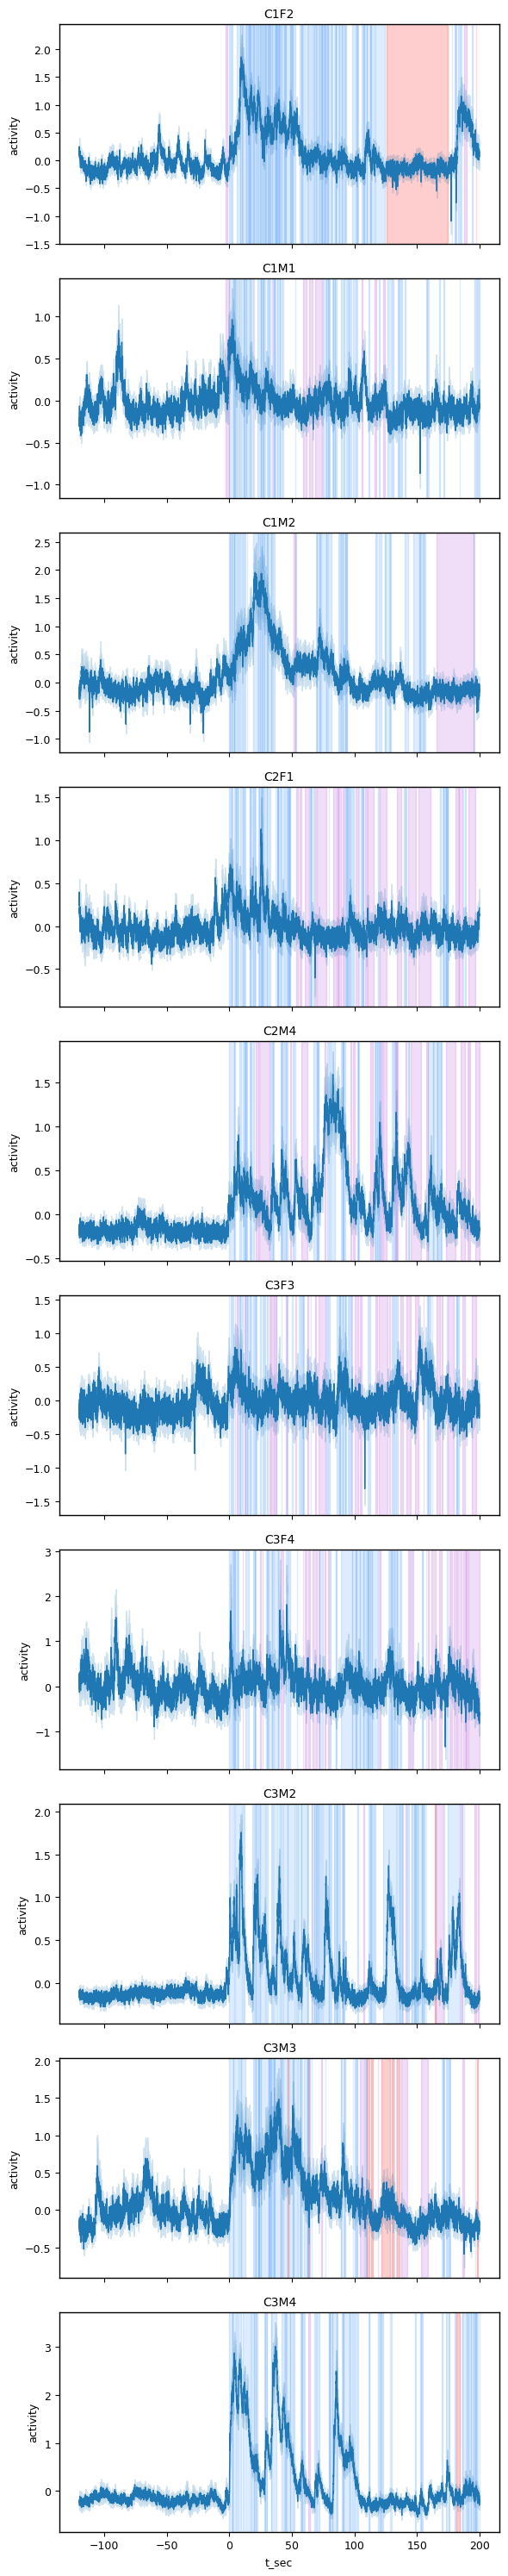

In [9]:
fig, axes = plt.subplots(len(animals), 1, figsize=(6, 3 * len(animals)), sharex=True)

for ax, a in zip(axes, animals):
    act = load_aligned_act(a, 'R1', traces_dir, behavior_csv, info_csv)
    intervals = build_intervals(a, 'R1', behavior_csv)
    t_first = pd.to_timedelta(first_interaction_time(a, 'R1', behavior_csv), unit='s')
    pop_mean, time = mean_population(act, intervals, window=(-5, 10), event_t=t_first)
    plot_pop_mean_eta(act, intervals, t_first, window=(-120, 200), ax=ax)
    ax.set_title(a)

plt.tight_layout()


In [10]:
t_first = pd.to_timedelta(first_interaction_time(a,'R1',behavior_csv),unit='s')
pop_mean,time = mean_population(act,intervals,window=(-5,10),
                           event_t = t_first)

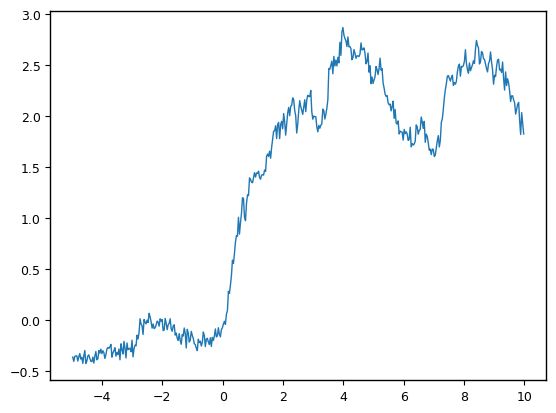

In [11]:
plt.plot(time,pop_mean)

In [12]:
from scipy.stats import zscore

In [13]:
animals

array(['C1F2', 'C1M1', 'C1M2', 'C2F1', 'C2M4', 'C3F3', 'C3F4', 'C3M2',
       'C3M3', 'C3M4'], dtype=object)

In [14]:

window = (-120, 120)

# sort: females first, then males
females = sorted([a for a in animals if 'F' in a])
males   = sorted([a for a in animals if 'M' in a])
sorted_animals = females + males
new_labels = [f'F{i+1}' for i in range(len(females))] + [f'M{i+1}' for i in range(len(males))]

heatmap_rows = []
common_time = None

for a in sorted_animals:
    act = load_aligned_act(a, 'R1', traces_dir, behavior_csv, info_csv)
    intervals = build_intervals(a, 'R1', behavior_csv)
    t_first = pd.to_timedelta(first_interaction_time(a, 'R1', behavior_csv), unit='s')

    roi_ids = act.columns.drop(['Behavior', 'behavior_type'])
    start = t_first + pd.Timedelta(seconds=window[0])
    end   = t_first + pd.Timedelta(seconds=window[1])
    ts = act.index.get_level_values('timestamp')
    act_sub = act.loc[(ts >= start) & (ts <= end), roi_ids]

    pop_mean = act_sub.mean(axis=1).values
    time_sec = (act_sub.index.get_level_values('timestamp') - t_first).total_seconds()

    if common_time is None:
        common_time = time_sec.values

    interp_mean = np.interp(common_time, time_sec.values, pop_mean)
    interp_mean = zscore(interp_mean)
    heatmap_rows.append(interp_mean)

heatmap_data = np.array(heatmap_rows)  # shape: (n_animals, n_timepoints)


/Users/amonast/opt/anaconda3/envs/caiman/lib/python3.10/site-packages/pandas/core/tools/datetimes.py:557: RuntimeWarning: invalid value encountered in cast
  arr, tz_parsed = tslib.array_with_unit_to_datetime(arg, unit, errors=errors)


FileNotFoundError: [Errno 2] No such file or directory: 'figures/population_mean_heatmap_animals.svg'

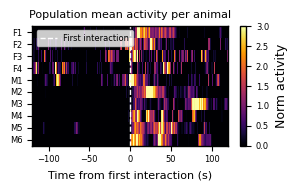

In [15]:

fig, ax = plt.subplots(figsize=(3.1,2))
im = ax.imshow(
    heatmap_data,
    aspect='auto',
    interpolation='nearest',
    vmin=0, vmax=3,
    extent=[common_time[0], common_time[-1], len(sorted_animals) - 0.5, -0.5],
    cmap='inferno',
)
cbar = plt.colorbar(im, ax=ax, label='Norm activity')
cbar.ax.tick_params(labelsize=6)
ax.set_yticks(range(len(sorted_animals)))
ax.set_yticklabels(new_labels,size=6)
ax.tick_params(axis='x', labelsize=6)
ax.axvline(0, color='white', linewidth=1, linestyle='--', label='First interaction')
ax.set_xlabel('Time from first interaction (s)',size=8)
ax.set_title('Population mean activity per animal',size=8)
ax.legend(loc='upper left', fontsize=6)
plt.tight_layout()
plt.savefig('figures/population_mean_heatmap_animals.svg',transparent=True)

# Plot population activity mean per behavior type

In [ ]:
for a in animals:
    act = load_aligned_act(a,'R2',
                           traces_dir,behavior_csv,info_csv)


/Users/amonast/opt/anaconda3/envs/caiman/lib/python3.10/site-packages/pandas/core/tools/datetimes.py:557: RuntimeWarning: invalid value encountered in cast
  arr, tz_parsed = tslib.array_with_unit_to_datetime(arg, unit, errors=errors)


In [ ]:
act

0         1         2  \
animal session timestamp                                                 
C0F2C  R2      0 days 00:00:00           -0.199963 -0.810772 -0.646396   
               0 days 00:00:00.066592256 -0.166492 -0.276906  0.977021   
               0 days 00:00:00.133184256 -0.387703  0.139787  0.356711   
               0 days 00:00:00.199775232 -0.016665  0.103394  0.081879   
               0 days 00:00:00.266367232  0.076759 -0.062964 -0.421952   
...                                            ...       ...       ...   
               0 days 00:12:59.986972160 -0.260032 -0.360646  0.400697   
               0 days 00:13:00.053563136 -0.416420 -0.337516 -0.286348   
               0 days 00:13:00.120155136 -0.654874 -0.569696 -0.828038   
               0 days 00:13:00.186746112 -0.408867  0.132502 -0.536221   
               0 days 00:13:00.253338112 -0.352291 -0.122925 -0.335973   

                                                 3         4         5  \
animal session timestamp                                                 
C0F2C  R2      0 days 00:00:00           -1.402246 -1.143476  0.187495   
               0 days 00:00:00.066592256 -1.016594 -1.206494 -0.527033   
               0 days 00:00:00.133184256 -2.015504 -0.274890  1.784929   
               0 days 00:00:00.199775232 -0.880914 -0.813919  0.137372   
               0 days 00:00:00.266367232 -0.468598  0.077668 -1.173774   
...                                            ...       ...       ...   
               0 days 00:12:59.986972160 -0.516566 -0.843798 -0.622333   
               0 days 00:13:00.053563136 -0.764526  0.239893  0.263442   
               0 days 00:13:00.120155136  1.082257 -1.174921  0.250127   
               0 days 00:13:00.186746112  0.191966 -0.380903 -0.071628   
               0 days 00:13:00.253338112 -0.099435 -0.246595 -0.044725   

                                                 6         7         8  \
animal session timestamp                                                 
C0F2C  R2      0 days 00:00:00           -0.863096 -0.895223 -0.517559   
               0 days 00:00:00.066592256 -1.168804 -0.445356 -0.343561   
               0 days 00:00:00.133184256 -0.762274  1.662353  0.307970   
               0 days 00:00:00.199775232 -0.647623 -1.224415 -0.290733   
               0 days 00:00:00.266367232 -0.649317 -0.340750  0.023116   
...                                            ...       ...       ...   
               0 days 00:12:59.986972160 -0.921634 -0.629607  0.200592   
               0 days 00:13:00.053563136 -0.313246 -0.539251  1.246347   
               0 days 00:13:00.120155136 -0.302625  0.170293  0.824444   
               0 days 00:13:00.186746112 -0.388837  0.232714  0.190131   
               0 days 00:13:00.253338112 -0.514551 -0.722047 -0.790809   

                                                 9  ...        59        60  \
animal session timestamp                            ...                       
C0F2C  R2      0 days 00:00:00           -0.003788  ... -0.082559  0.555983   
               0 days 00:00:00.066592256 -1.502900  ...  0.507574  1.153667   
               0 days 00:00:00.133184256 -1.080075  ... -1.090712 -0.038364   
               0 days 00:00:00.199775232 -0.409279  ... -1.008220 -0.021242   
               0 days 00:00:00.266367232 -0.424903  ...  0.460146  0.241332   
...                                            ...  ...       ...       ...   
               0 days 00:12:59.986972160 -0.539222  ...  0.909893  0.283105   
               0 days 00:13:00.053563136 -0.105551  ... -0.497283  0.498410   
               0 days 00:13:00.120155136  0.618732  ... -0.031024 -0.178274   
               0 days 00:13:00.186746112 -0.341116  ... -0.141559  0.055130   
               0 days 00:13:00.253338112  0.725874  ... -0.935170  0.576527   

                                                61        62        63  \
animal session timestamp                                  

In [ ]:
intervals

,animal,session,Behavior,behavior_type,start,end
0,C0F2C,R2,Face Sniffing,Pro-Social,179.412,182.947
1,C0F2C,R2,Body Sniffing,Pro-Social,183.147,184.248
2,C0F2C,R2,Face Sniffing,Pro-Social,184.314,184.615
3,C0F2C,R2,Body Sniffing,Pro-Social,184.781,186.582
4,C0F2C,R2,Anogenital Sniffing,Pro-Social,186.815,186.849
...,...,...,...,...,...,...
164,C0F2C,R2,Body Sniffing,Pro-Social,763.202,763.469
165,C0F2C,R2,Face Sniffing,Pro-Social,763.569,763.903
166,C0F2C,R2,Body Sniffing,Pro-Social,763.936,764.069
167,C0F2C,R2,Tail Sniffing,Pro-Social,764.169,764.303


In [ ]:
add_behavior_type_index(act,intervals,)

0         1  \
animal session timestamp                 behavior_type                          
C0F2C  R2      0 days 00:00:00           Other            -0.199963 -0.810772   
               0 days 00:00:00.066592256 Other            -0.166492 -0.276906   
               0 days 00:00:00.133184256 Other            -0.387703  0.139787   
               0 days 00:00:00.199775232 Other            -0.016665  0.103394   
               0 days 00:00:00.266367232 Other             0.076759 -0.062964   
...                                                             ...       ...   
               0 days 00:12:59.986972160 Social Avoidance -0.260032 -0.360646   
               0 days 00:13:00.053563136 Social Avoidance -0.416420 -0.337516   
               0 days 00:13:00.120155136 Social Avoidance -0.654874 -0.569696   
               0 days 00:13:00.186746112 Social Avoidance -0.408867  0.132502   
               0 days 00:13:00.253338112 Social Avoidance -0.352291 -0.122925   

                                                                  2         3  \
animal session timestamp                 behavior_type                          
C0F2C  R2      0 days 00:00:00           Other            -0.646396 -1.402246   
               0 days 00:00:00.066592256 Other             0.977021 -1.016594   
               0 days 00:00:00.133184256 Other             0.356711 -2.015504   
               0 days 00:00:00.199775232 Other             0.081879 -0.880914   
               0 days 00:00:00.266367232 Other            -0.421952 -0.468598   
...                                                             ...       ...   
               0 days 00:12:59.986972160 Social Avoidance  0.400697 -0.516566   
               0 days 00:13:00.053563136 Social Avoidance -0.286348 -0.764526   
               0 days 00:13:00.120155136 Social Avoidance -0.828038  1.082257   
               0 days 00:13:00.186746112 Social Avoidance -0.536221  0.191966   
               0 days 00:13:00.253338112 Social Avoidance -0.335973 -0.099435   

                                                                  4         5  \
animal session timestamp                 behavior_type                          
C0F2C  R2      0 days 00:00:00           Other            -1.143476  0.187495   
               0 days 00:00:00.066592256 Other            -1.206494 -0.527033   
               0 days 00:00:00.133184256 Other            -0.274890  1.784929   
               0 days 00:00:00.199775232 Other            -0.813919  0.137372   
               0 days 00:00:00.266367232 Other             0.077668 -1.173774   
...                                                             ...       ...   
               0 days 00:12:59.986972160 Social Avoidance -0.843798 -0.622333   
               0 days 00:13:00.053563136 Social Avoidance  0.239893  0.263442   
               0 days 00:13:00.120155136 Social Avoidance -1.174921  0.250127   
               0 days 00:13:00.186746112 Social Avoidance -0.380903 -0.071628   
               0 days 00:13:00.253338112 Social Avoidance -0.246595 -0.044725   

                                                                  6         7  \
animal session timestamp                 behavior_type                          
C0F2C  R2      0 days 00:00:00           Other            -0.863096 -0.895223   
               0 days 00:00:00.066592256 Other            -1.168804 -0.445356   
               0 days 00:00:00.133184256 Other            -0.762274  1.662353   
               0 days 00:00:00.199775232 Other            -0.647623 -1.224415   
               0 days 00:00:00.266367232 Other            -0.649317 -0.340750   
...                                                             ...       ...   
               0 days 00:12:59.986972160 Social Avoidance -0.921634 -0.629607   
               0 days 00:13:00.053563136 Social Avoidance -0.313246 -0.539251   
               0 days 00:13:00.120155136 Social Avoidance -0.302625  0.170293   
             

In [ ]:
act = act.set_index(['Behavior', 'behavior_type'], append=True)

/Users/amonast/opt/anaconda3/envs/caiman/lib/python3.10/site-packages/pandas/core/tools/datetimes.py:557: RuntimeWarning: invalid value encountered in cast
  arr, tz_parsed = tslib.array_with_unit_to_datetime(arg, unit, errors=errors)


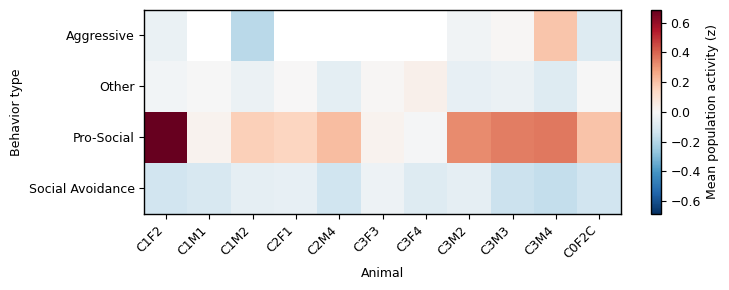

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pop_means = {}
for a in animals:
    act = load_aligned_act(a, 'R2', traces_dir, behavior_csv, info_csv)
    act = act.set_index(['Behavior', 'behavior_type'], append=True)

    pop = act.mean(axis=1)                       # mean across cells, per frame
    pop_means[a] = pop.groupby(level='behavior_type').mean()  # mean over frames per behavior type

pop_df = pd.DataFrame(pop_means)   # rows: behavior_type, columns: animals
pop_arr = pop_df.to_numpy()        # plain array, same layout

# heatmap
lim = np.nanmax(np.abs(pop_arr))
fig, ax = plt.subplots(figsize=(1 + 0.6 * pop_df.shape[1], 1 + 0.5 * pop_df.shape[0]))
im = ax.imshow(pop_arr, cmap='RdBu_r', vmin=-lim, vmax=lim, aspect='auto')
ax.set_xticks(range(pop_df.shape[1]), pop_df.columns, rotation=45, ha='right')
ax.set_yticks(range(pop_df.shape[0]), pop_df.index)
ax.set_xlabel('Animal')
ax.set_ylabel('Behavior type')
fig.colorbar(im, ax=ax, label='Mean population activity (z)')
fig.tight_layout()
fig.savefig('pop_activity_by_behavior_type.png', dpi=300)

# Plot tuned cells mean activities across types of behavior


In [ ]:
from load_traces import get_tuned_df
data_dir = '/Users/amonast/Desktop/miniscope/data'


In [ ]:
tuned, _ = get_tuned_df(animals, data_dir, sessions=['R2'])
tuned = tuned.set_index(['animal', 'session', 'behavior_type'])['tuned_cells']

pop_means = {}
n_tuned = {}
for a in animals:
    act = load_aligned_act(a, 'R2', traces_dir, behavior_csv, info_csv)
    act = act.set_index(['Behavior', 'behavior_type'], append=True)

    row, counts = {}, {}
    for bt, frames in act.groupby(level='behavior_type'):
        cells = tuned.get((a, 'R2', bt), [])
        counts[bt] = len(cells)
        row[bt] = frames[cells].mean(axis=1).mean() if cells else np.nan

    pop_means[a] = pd.Series(row)
    n_tuned[a] = pd.Series(counts)

pop_df = pd.DataFrame(pop_means)   # rows: behavior_type, columns: animals
n_tuned_df = pd.DataFrame(n_tuned)
pop_arr = pop_df.to_numpy()

/Users/amonast/opt/anaconda3/envs/caiman/lib/python3.10/site-packages/pandas/core/tools/datetimes.py:557: RuntimeWarning: invalid value encountered in cast
  arr, tz_parsed = tslib.array_with_unit_to_datetime(arg, unit, errors=errors)


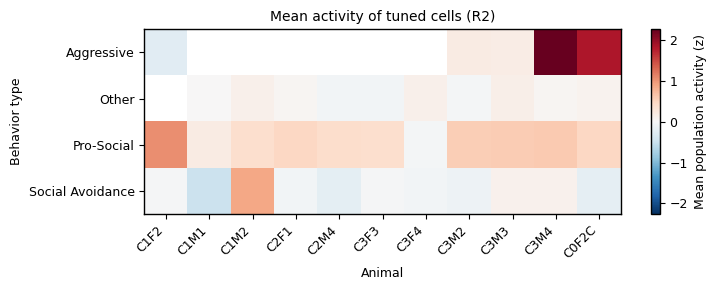

In [ ]:
lim = np.nanmax(np.abs(pop_arr))
fig, ax = plt.subplots(figsize=(1 + 0.6 * pop_df.shape[1], 1 + 0.5 * pop_df.shape[0]))
im = ax.imshow(pop_arr, cmap='RdBu_r', vmin=-lim, vmax=lim, aspect='auto')
ax.set_xticks(range(pop_df.shape[1]), pop_df.columns, rotation=45, ha='right')
ax.set_yticks(range(pop_df.shape[0]), pop_df.index)
ax.set_xlabel('Animal')
ax.set_ylabel('Behavior type')
ax.set_title('Mean activity of tuned cells (R2)')
fig.colorbar(im, ax=ax, label='Mean population activity (z)')
fig.tight_layout()
fig.savefig('tuned_pop_activity_by_behavior_type.png', dpi=300)

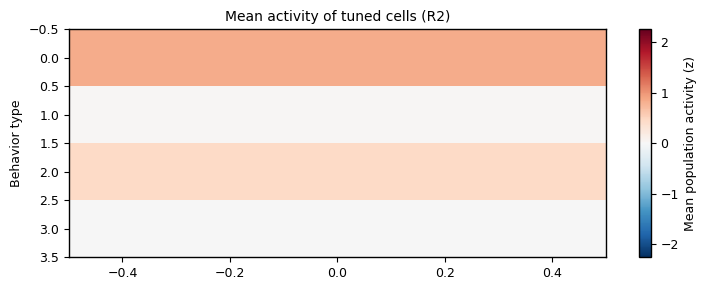

In [ ]:
mean_pop_arr = np.expand_dims(np.nanmean(pop_arr,axis=1),axis=1)
fig, ax = plt.subplots(figsize=(1 + 0.6 * pop_df.shape[1], 1 + 0.5 * pop_df.shape[0]))
im = ax.imshow(mean_pop_arr, cmap='RdBu_r', vmin=-lim, vmax=lim, aspect='auto')
ax.set_ylabel('Behavior type')
ax.set_title('Mean activity of tuned cells (R2)')
fig.colorbar(im, ax=ax, label='Mean population activity (z)')
fig.tight_layout()
fig.savefig('tuned_pop_activity_by_behavior_type_meanacrossanimals.png', dpi=300)